# Week 8 · Networks

1,478 posts from one MOOC discussion forum. 311 people.

Run the cell below.

In [1]:
%matplotlib inline
import pandas as pd, networkx as nx, matplotlib.pyplot as plt, numpy as np, itertools
from sklearn.metrics import adjusted_mutual_info_score

BASE = "https://raw.githubusercontent.com/HakeoungLee/edis8100-datasets/main/edx-mooc-forum"
posts = pd.read_csv(f"{BASE}/posts.csv")
author_of = dict(zip(posts.post_id, posts.author))

print(f"{len(posts):,} posts | {posts.author.nunique()} people | {posts.category_name.nunique()} categories")
display(posts[["author", "category_name", "parent_post_id", "title"]].head(5))

1,478 posts | 311 people | 124 categories


,author,category_name,parent_post_id,title
0,d96db92845537eddb7c559e8de578ed12b075cad4c390a...,Week 1 / Execution Errors in Codeboard (non gr...,571f77b5d11155053000028c,NaN
1,4803b5fbbb47bd749a46cb2f873b3746e2ae6ff30a0a94...,Week 0 / 0 Introductions,NaN,INTRODUCING MYSELF..
2,f4f5300843bfd2c87a3248e731e6ec9c183e1b0eca545f...,Week 0 / 0 Introductions,571f715f7e622b05750002ae,NaN
3,f4f5300843bfd2c87a3248e731e6ec9c183e1b0eca545f...,Week 0 / 0 Introductions,NaN,Hii
4,d3e3caaf58986db9aa1cefc296f77a279b4a2e80e9eeed...,Week 0 / 0 Introductions,NaN,Welcome all


## 1. One network

Nothing in this file says who is connected to whom. It is a list of posts. You decide when two people count as tied, and that decision is the rule.

**A and B are tied if one replied to a post by the other.**

In the picture, **degree** is how many people someone is tied to.

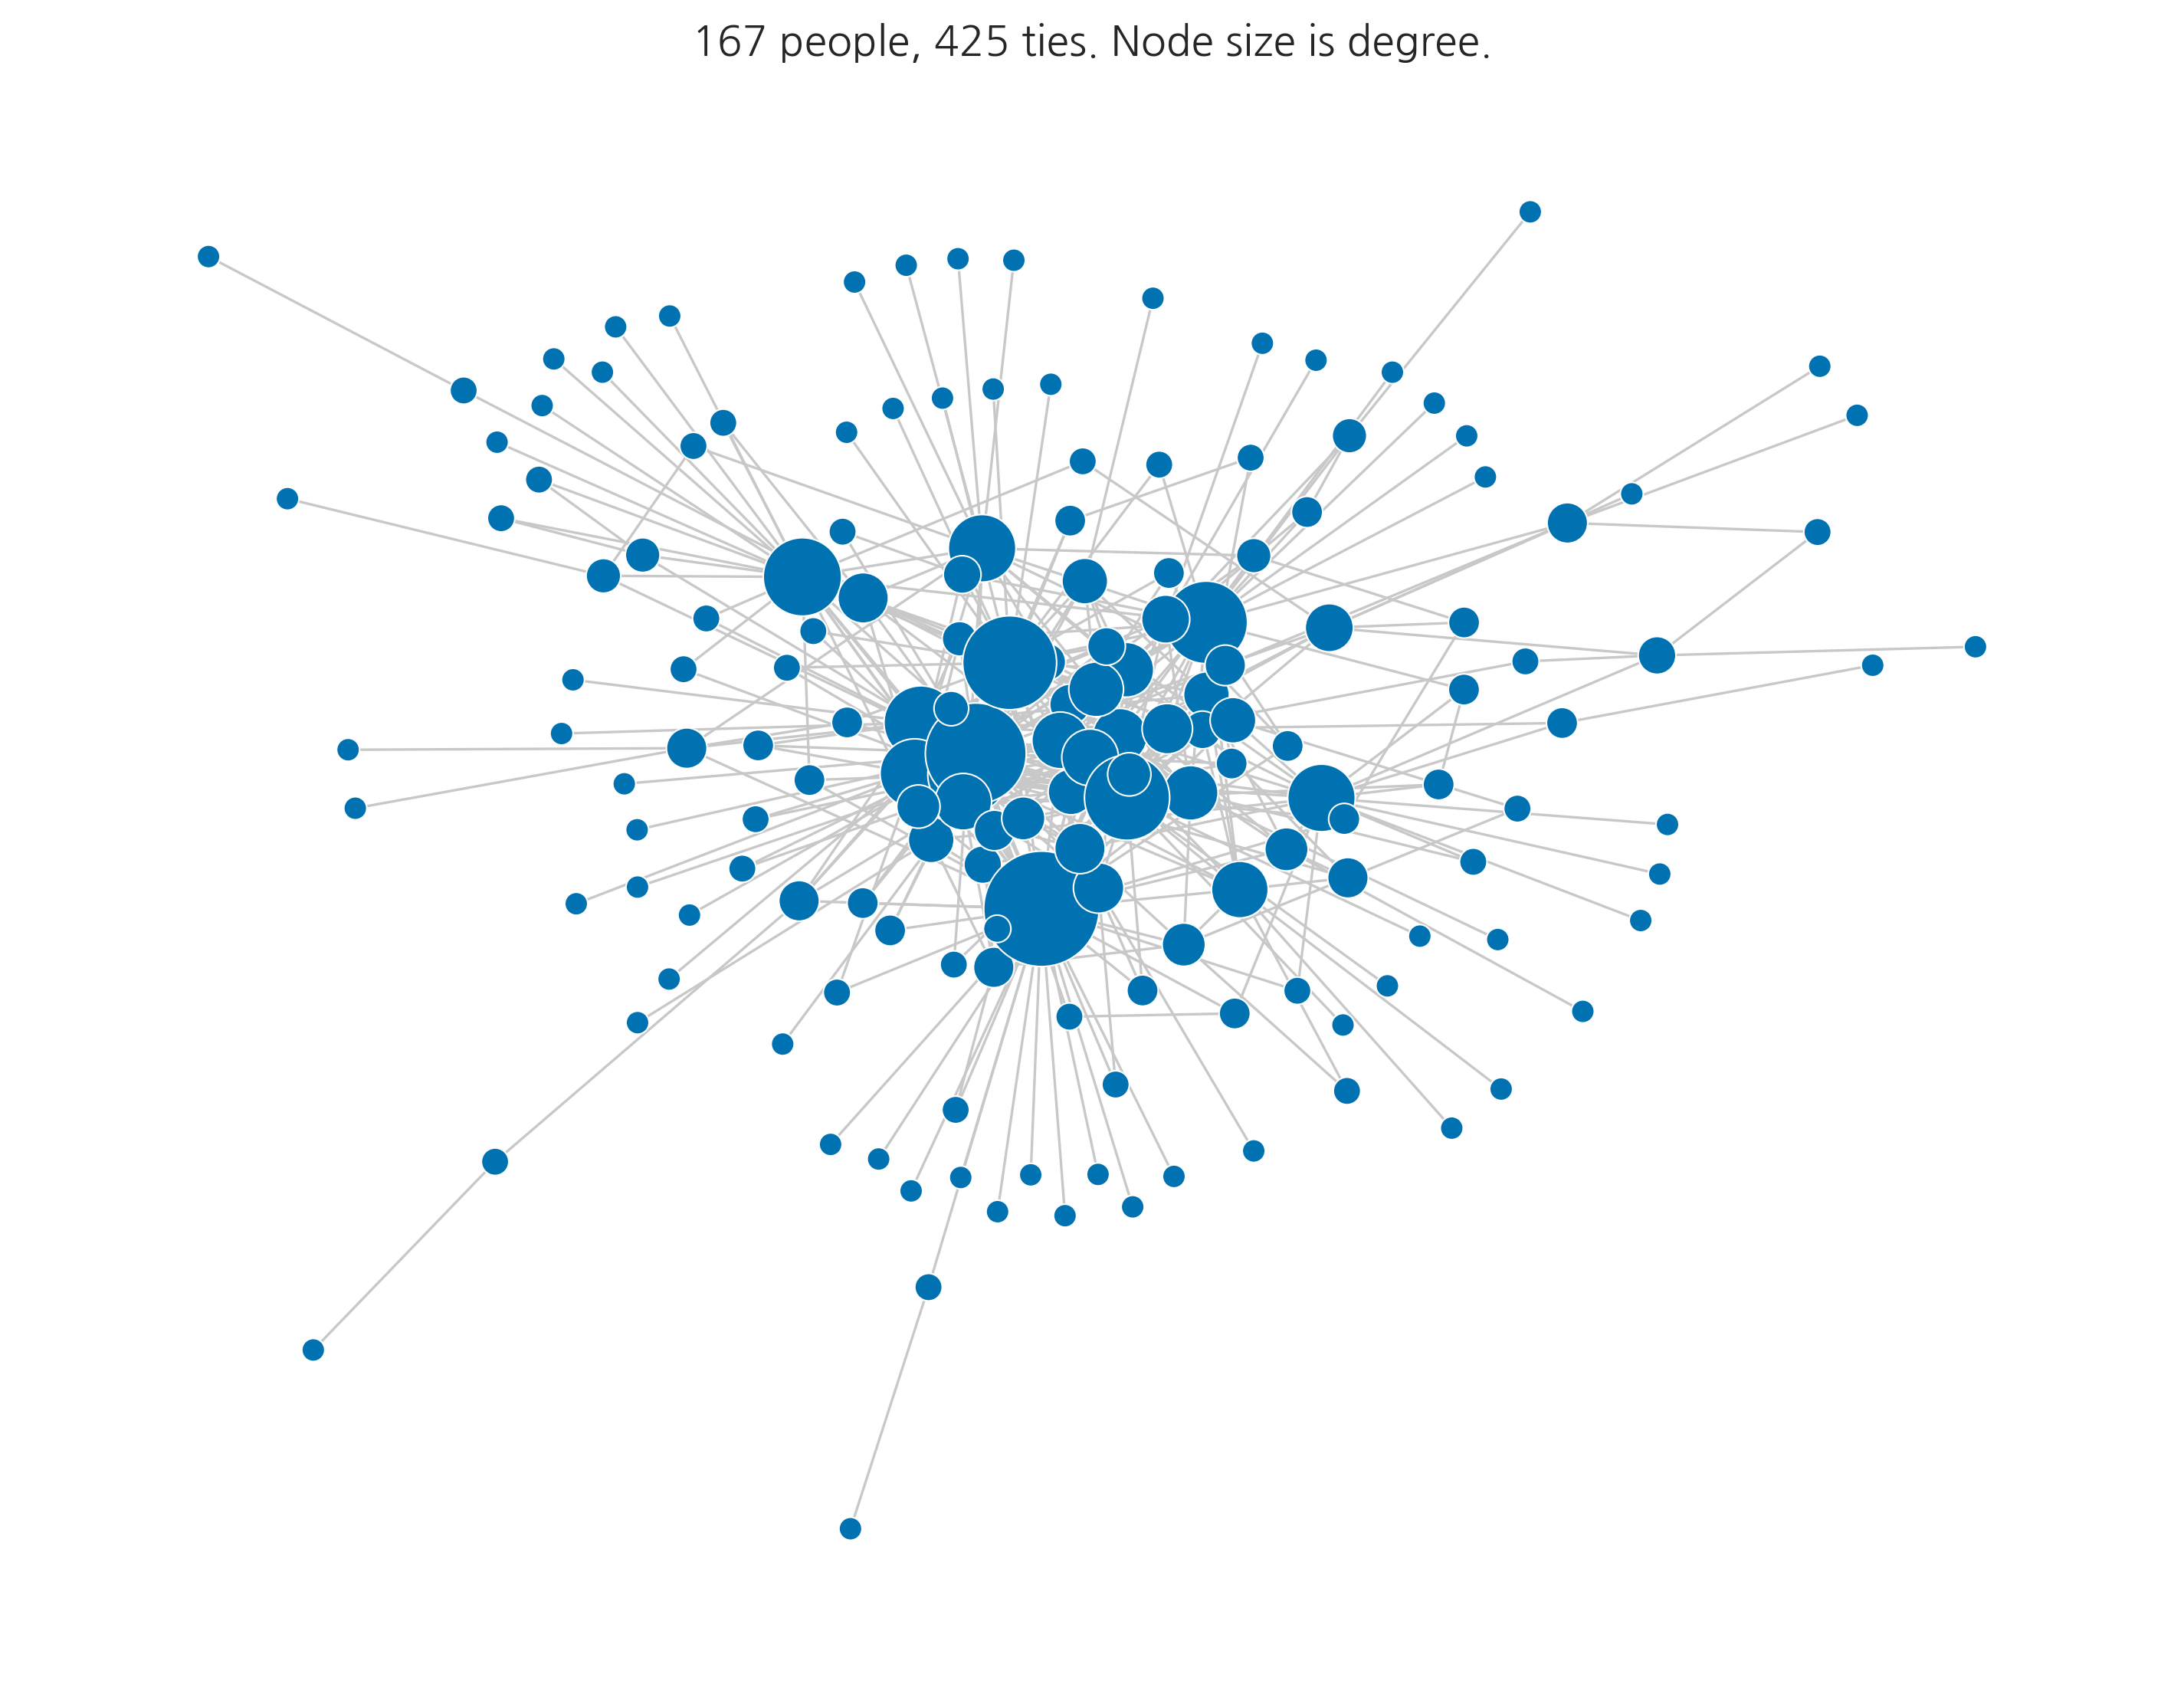

181 people made at least one tie.
130 people posted and made none. They are not in the picture.


In [2]:
def reply_network(df):
    G = nx.Graph()
    for _, r in df.dropna(subset=["parent_post_id"]).iterrows():
        target = author_of.get(r.parent_post_id)
        if target and target != r.author:
            G.add_edge(r.author, target)
    return G

G = reply_network(posts)
LCC = G.subgraph(max(nx.connected_components(G), key=len)).copy()
pos = nx.spring_layout(LCC, seed=8100, k=0.55, iterations=300)
deg = dict(LCC.degree())

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(LCC, pos, ax=ax, edge_color="#c8c8c8", width=0.8)
nx.draw_networkx_nodes(LCC, pos, ax=ax, node_color="#0072b2",
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.5)
ax.set_title(f"{LCC.number_of_nodes()} people, {LCC.number_of_edges()} ties. "
             f"Node size is degree.", fontsize=13)
ax.axis("off"); plt.show()

print(f"{G.number_of_nodes()} people made at least one tie.")
print(f"{posts.author.nunique() - G.number_of_nodes()} people posted and made none. "
      f"They are not in the picture.")

**What do you see?**

## 2. The same people, a different rule

Two more rules on the same 1,478 posts.

- **replied to** one of their posts
- **posted in the same thread**
- **posted in the same category**

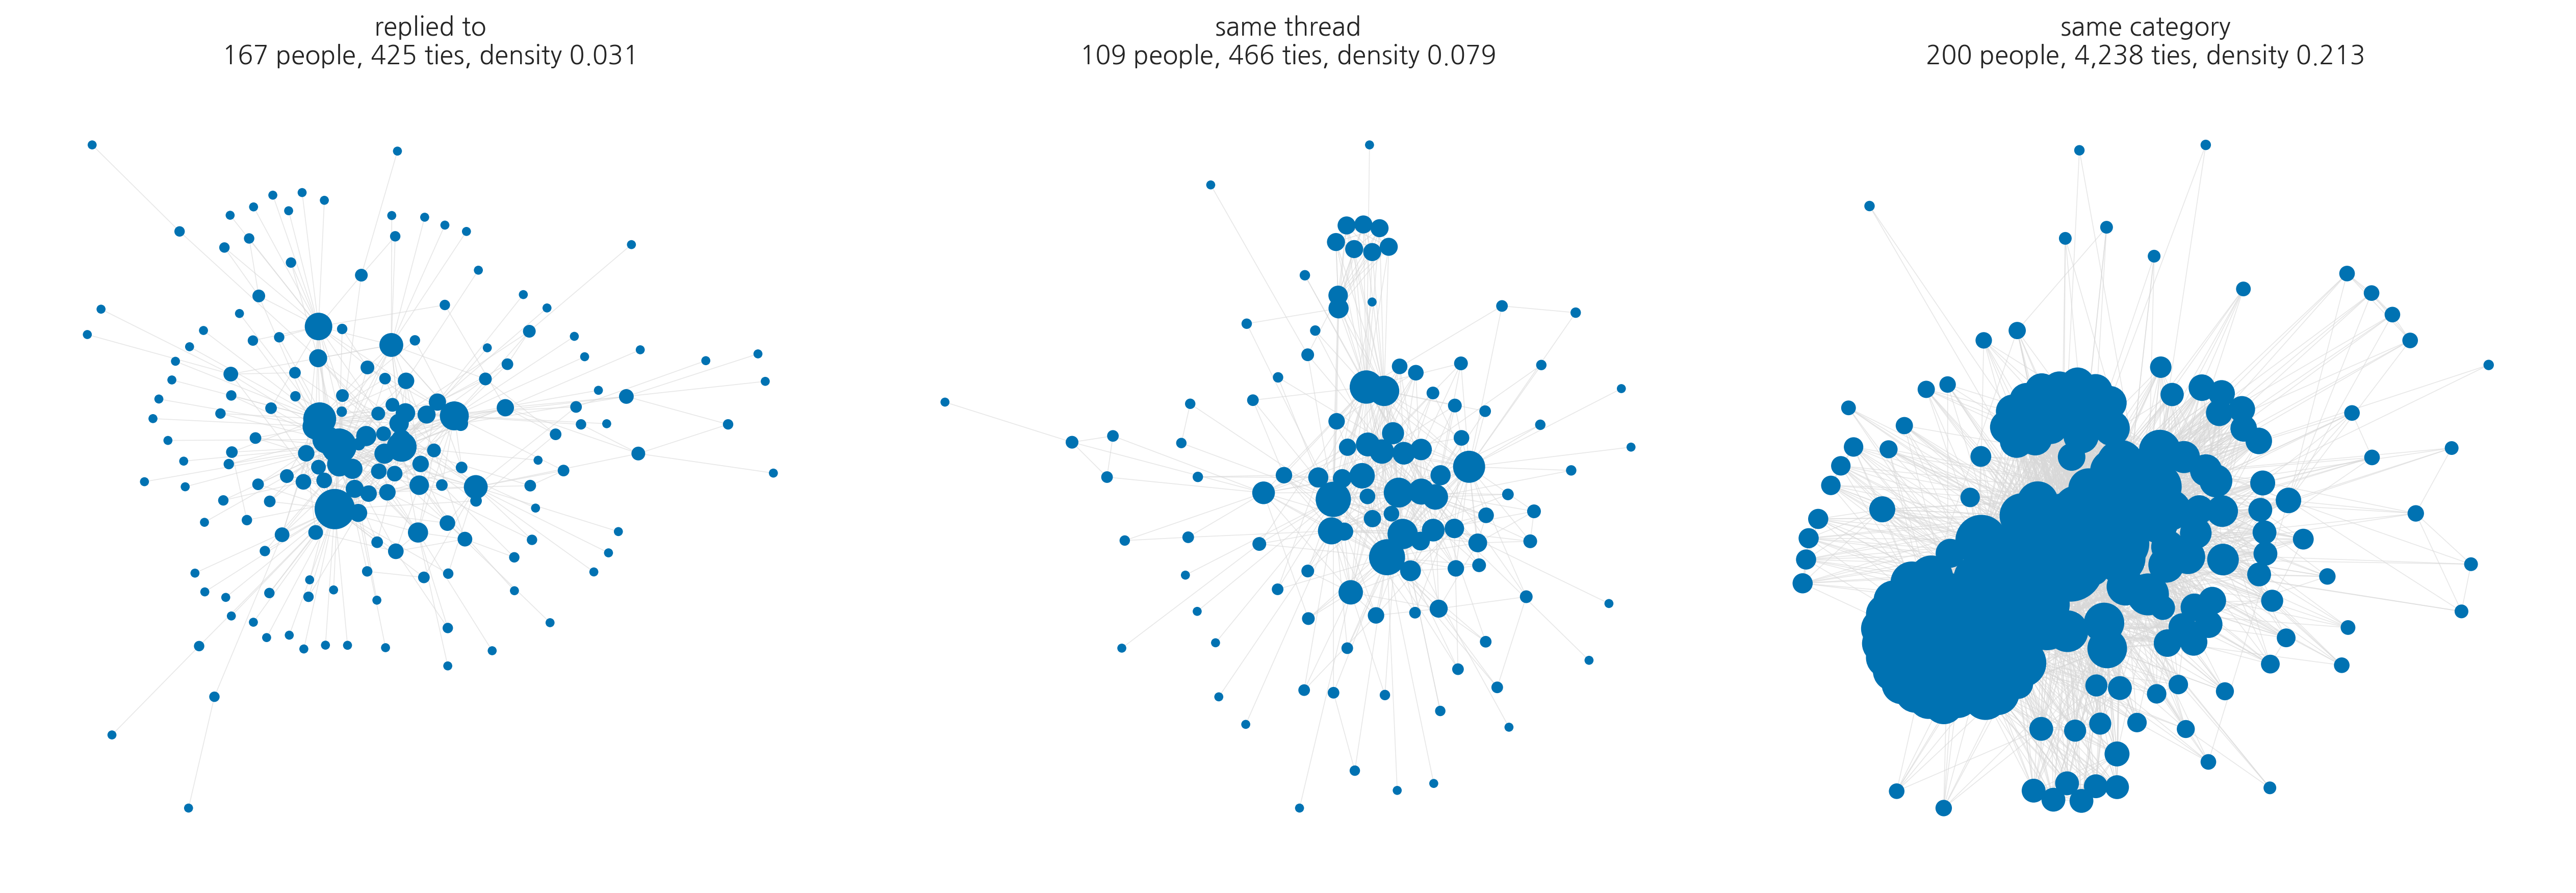

In [3]:
def thread_network(df):
    G = nx.Graph()
    for _, g in df.groupby("thread_id"):
        for a, b in itertools.combinations(sorted(set(g.author.dropna())), 2):
            G.add_edge(a, b)
    return G

def category_network(df):
    G = nx.Graph()
    for _, g in df.groupby("category_name"):
        people = sorted(set(g.author.dropna()))
        if len(people) <= 120:
            for a, b in itertools.combinations(people, 2):
                G.add_edge(a, b)
    return G

nets = {"replied to": G, "same thread": thread_network(posts), "same category": category_network(posts)}

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (name, H) in zip(axes, nets.items()):
    K = H.subgraph(max(nx.connected_components(H), key=len)).copy()
    p = nx.spring_layout(K, seed=8100, k=0.5, iterations=200)
    d = dict(K.degree())
    nx.draw_networkx_edges(K, p, ax=ax, edge_color="#d8d8d8", width=0.4, alpha=.6)
    nx.draw_networkx_nodes(K, p, ax=ax, node_color="#0072b2",
                           node_size=[12 + 6 * d[n] for n in K.nodes()], linewidths=0)
    ax.set_title(f"{name}\n{K.number_of_nodes()} people, {K.number_of_edges():,} ties, "
                 f"density {nx.density(K):.3f}", fontsize=12)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Same posts, same people. Which of these three would you use, and for what question?**

## 3. Communities

A **community** is a set of people tied to each other more than to the rest of the network. The algorithm finds them from the ties alone.

It will return communities from any network, including one with ties drawn at random, so getting communities is not itself a finding.

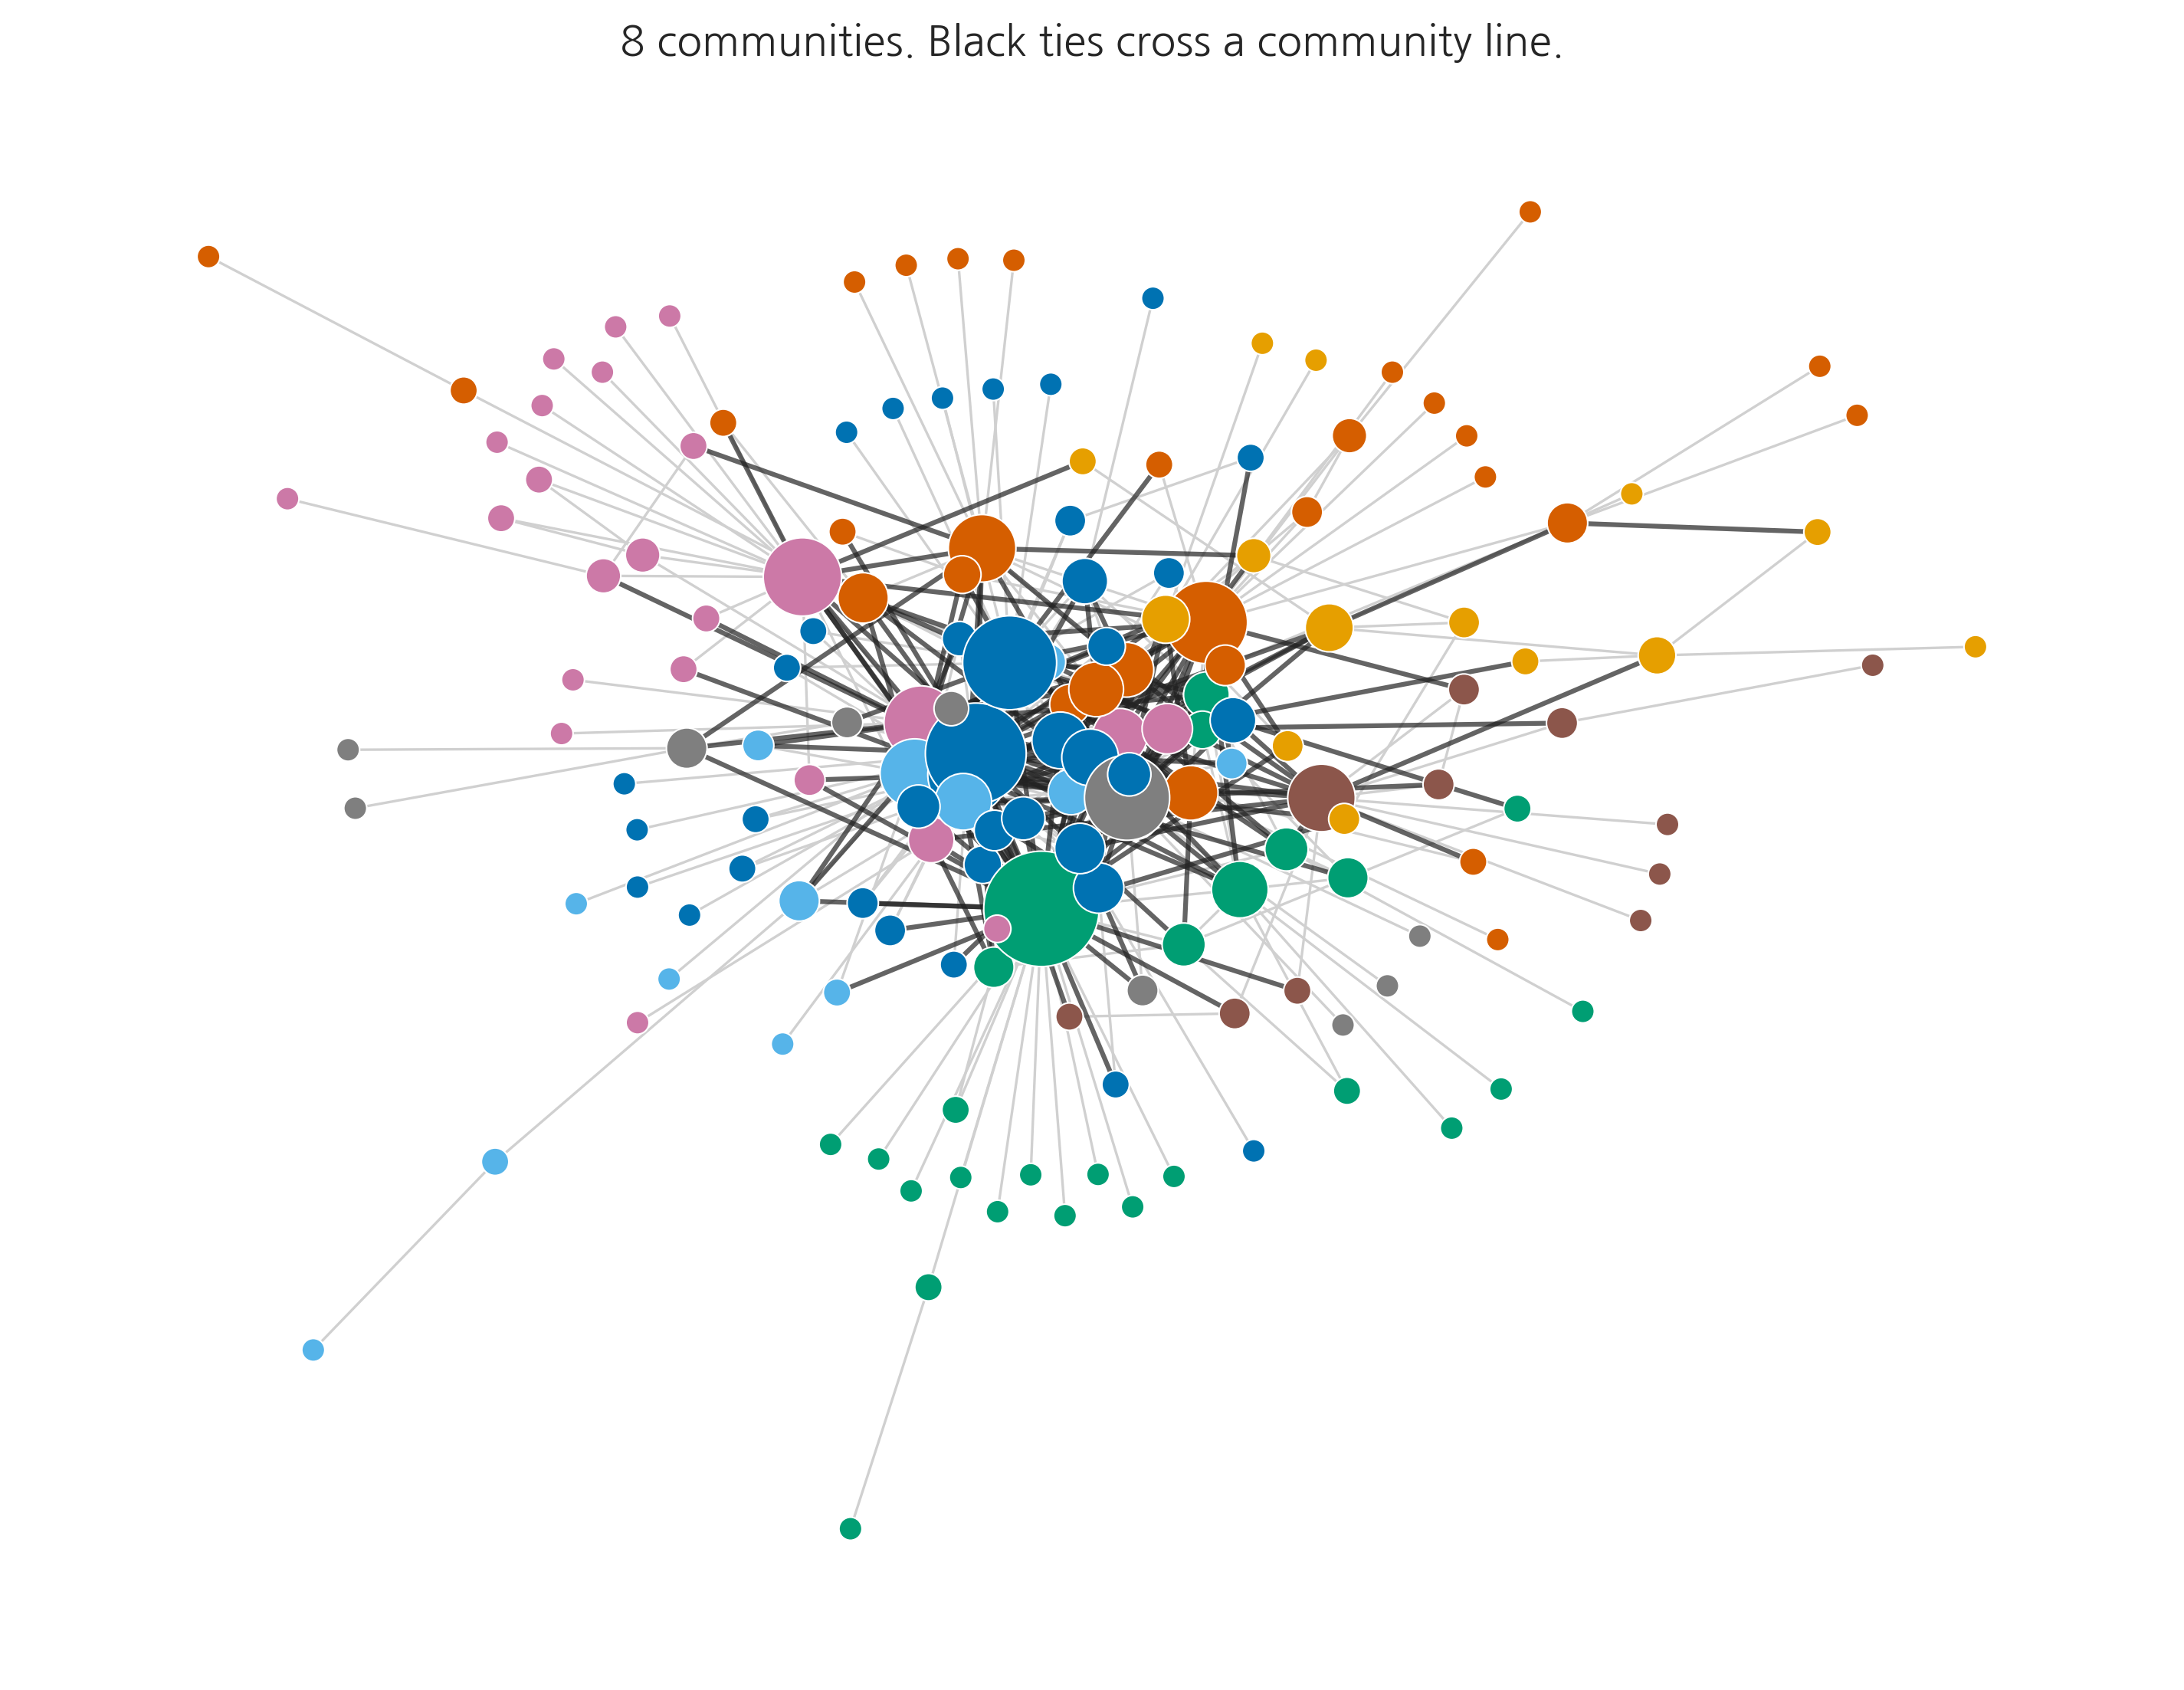

sizes: [39, 30, 26, 24, 14, 13, 11, 10]
modularity 0.355


In [4]:
communities = list(nx.community.greedy_modularity_communities(LCC))
community_of = {n: i for i, c in enumerate(communities) for n in c}
COLORS = ["#0072b2", "#d55e00", "#009e73", "#cc79a7", "#e69f00", "#56b4e9", "#8c564b", "#7f7f7f"]

within = [(a, b) for a, b in LCC.edges() if community_of[a] == community_of[b]]
across  = [(a, b) for a, b in LCC.edges() if community_of[a] != community_of[b]]

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(LCC, pos, edgelist=within, ax=ax, edge_color="#d0d0d0", width=0.8)
nx.draw_networkx_edges(LCC, pos, edgelist=across, ax=ax, edge_color="#222222", width=1.5, alpha=.7)
nx.draw_networkx_nodes(LCC, pos, ax=ax,
                       node_color=[COLORS[community_of[n] % len(COLORS)] for n in LCC.nodes()],
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.5)
ax.set_title(f"{len(communities)} communities. Black ties cross a community line.", fontsize=13)
ax.axis("off"); plt.show()

print("sizes:", [len(c) for c in communities])
print(f"modularity {nx.community.modularity(LCC, communities):.3f}")

## 4. Are the communities topics?

The forum has categories. If the communities are topics, people in one community should post mostly in one category.

In [5]:
main_category = (posts.groupby(["author", "category_name"]).size().reset_index(name="n")
                 .sort_values("n", ascending=False).drop_duplicates("author")
                 .set_index("author").category_name.to_dict())

rows = []
for i, c in enumerate(communities):
    cats = pd.Series([main_category[n] for n in c if n in main_category]).value_counts()
    rows.append({"community": i, "people": len(c),
                 "most common category": cats.index[0],
                 "how many of them": f"{cats.iloc[0]} of {cats.sum()}"})
display(pd.DataFrame(rows))

nodes = [n for n in LCC.nodes() if n in main_category]
score = adjusted_mutual_info_score([community_of[n] for n in nodes],
                                   [main_category[n] for n in nodes])
print(f"\nAgreement between communities and categories: {score:.3f}")
print("(0 is what you get from unrelated groupings, 1 is a perfect match.)")

,community,people,most common category,how many of them
0,0,39,Week 2 / Exam 2,4 of 39
1,1,30,Week 0 / 0 Introductions,6 of 25
2,2,26,Week 0 / 0 Introductions,6 of 26
3,3,24,Any Question? / General,12 of 24
4,4,14,Any Questions? / Technical Help,3 of 13
5,5,13,Week 0 / 0 Introductions,4 of 13
6,6,11,Any Question? / General,3 of 11
7,7,10,Week 2 / Reasoning II (non graded activity),2 of 10



Agreement between communities and categories: 0.070
(0 is what you get from unrelated groupings, 1 is a perfect match.)


## 5. Degree centrality

Poquet and Joksimovic (2022) write that in online learner interaction, centrality is often a proxy for how active someone was rather than for their position among others.

The eight largest degrees, and how many posts those people wrote.

,degree,betweenness,posts written
0,58.0,0.305,132
1,44.0,0.191,89
2,38.0,0.120,57
3,31.0,0.090,82
4,29.0,0.142,48
5,27.0,0.069,56
6,26.0,0.135,33
7,23.0,0.060,25


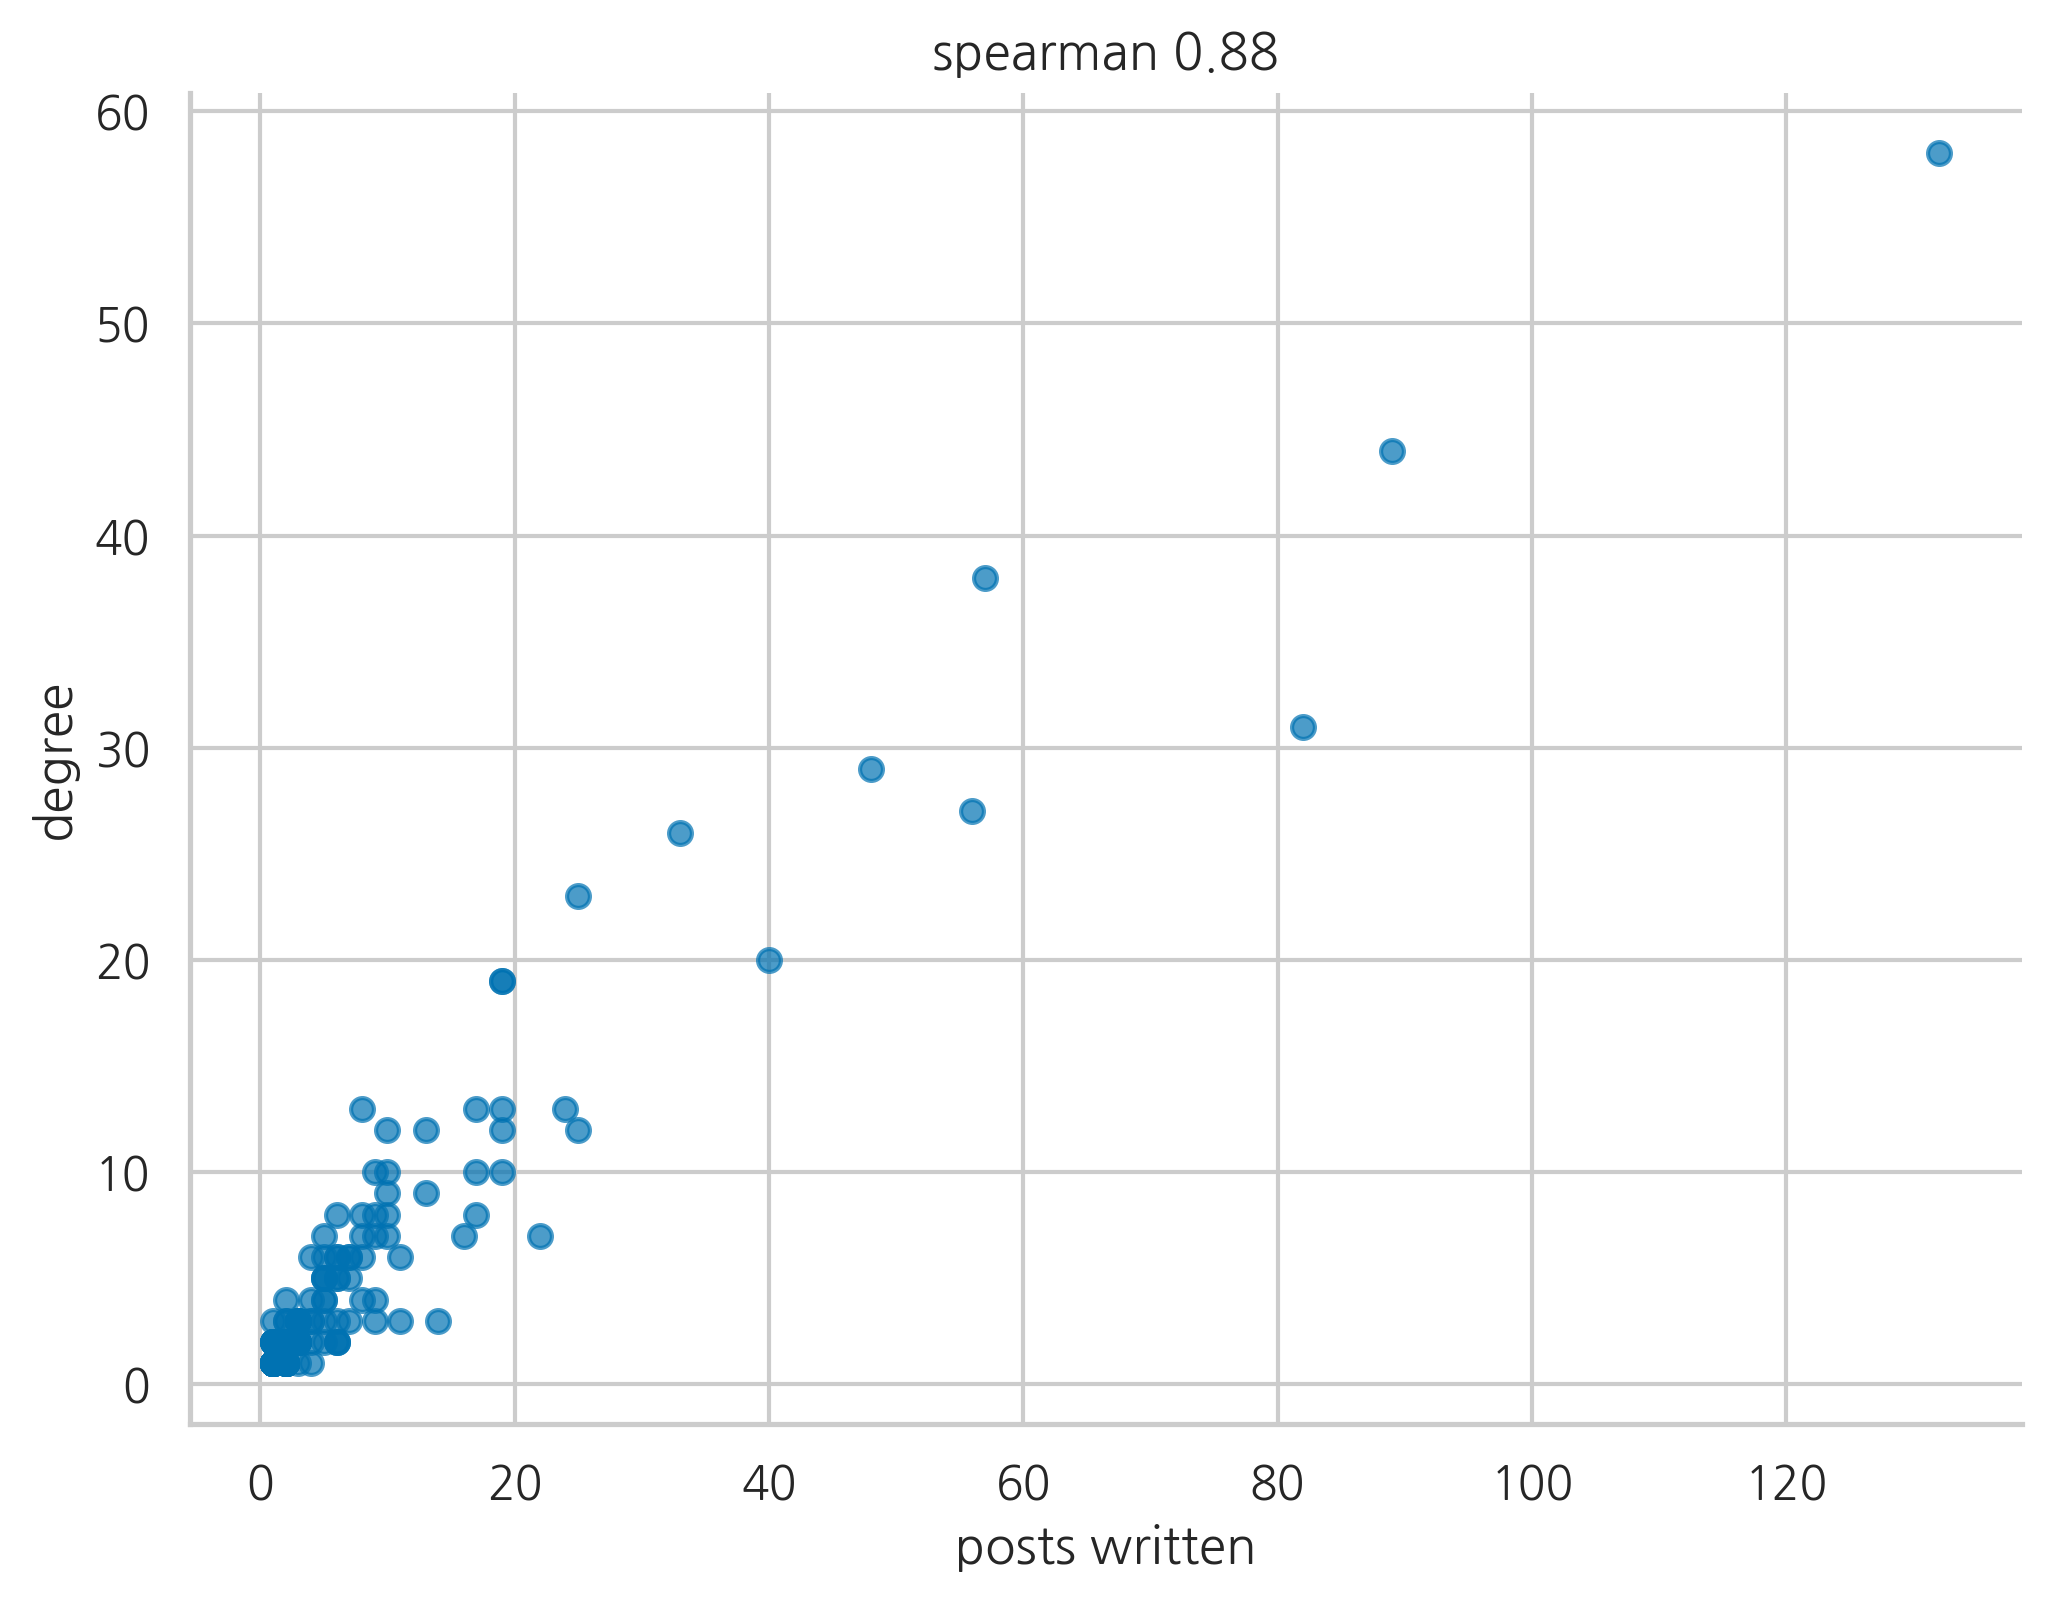

In [6]:
cent = pd.DataFrame({
    "degree": pd.Series(deg),
    "betweenness": pd.Series(nx.betweenness_centrality(LCC)),
    "posts written": posts.author.value_counts(),
}).dropna().sort_values("degree", ascending=False)

display(cent.head(8).round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(cent["posts written"], cent["degree"], s=30, color="#0072b2", alpha=.7)
ax.set_xlabel("posts written"); ax.set_ylabel("degree")
ax.set_title(f"spearman {cent['degree'].corr(cent['posts written'], method='spearman'):.2f}",
             fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Change the rule

`MIN_REPLIES` keeps a tie only if the two people replied to each other at least this many times.

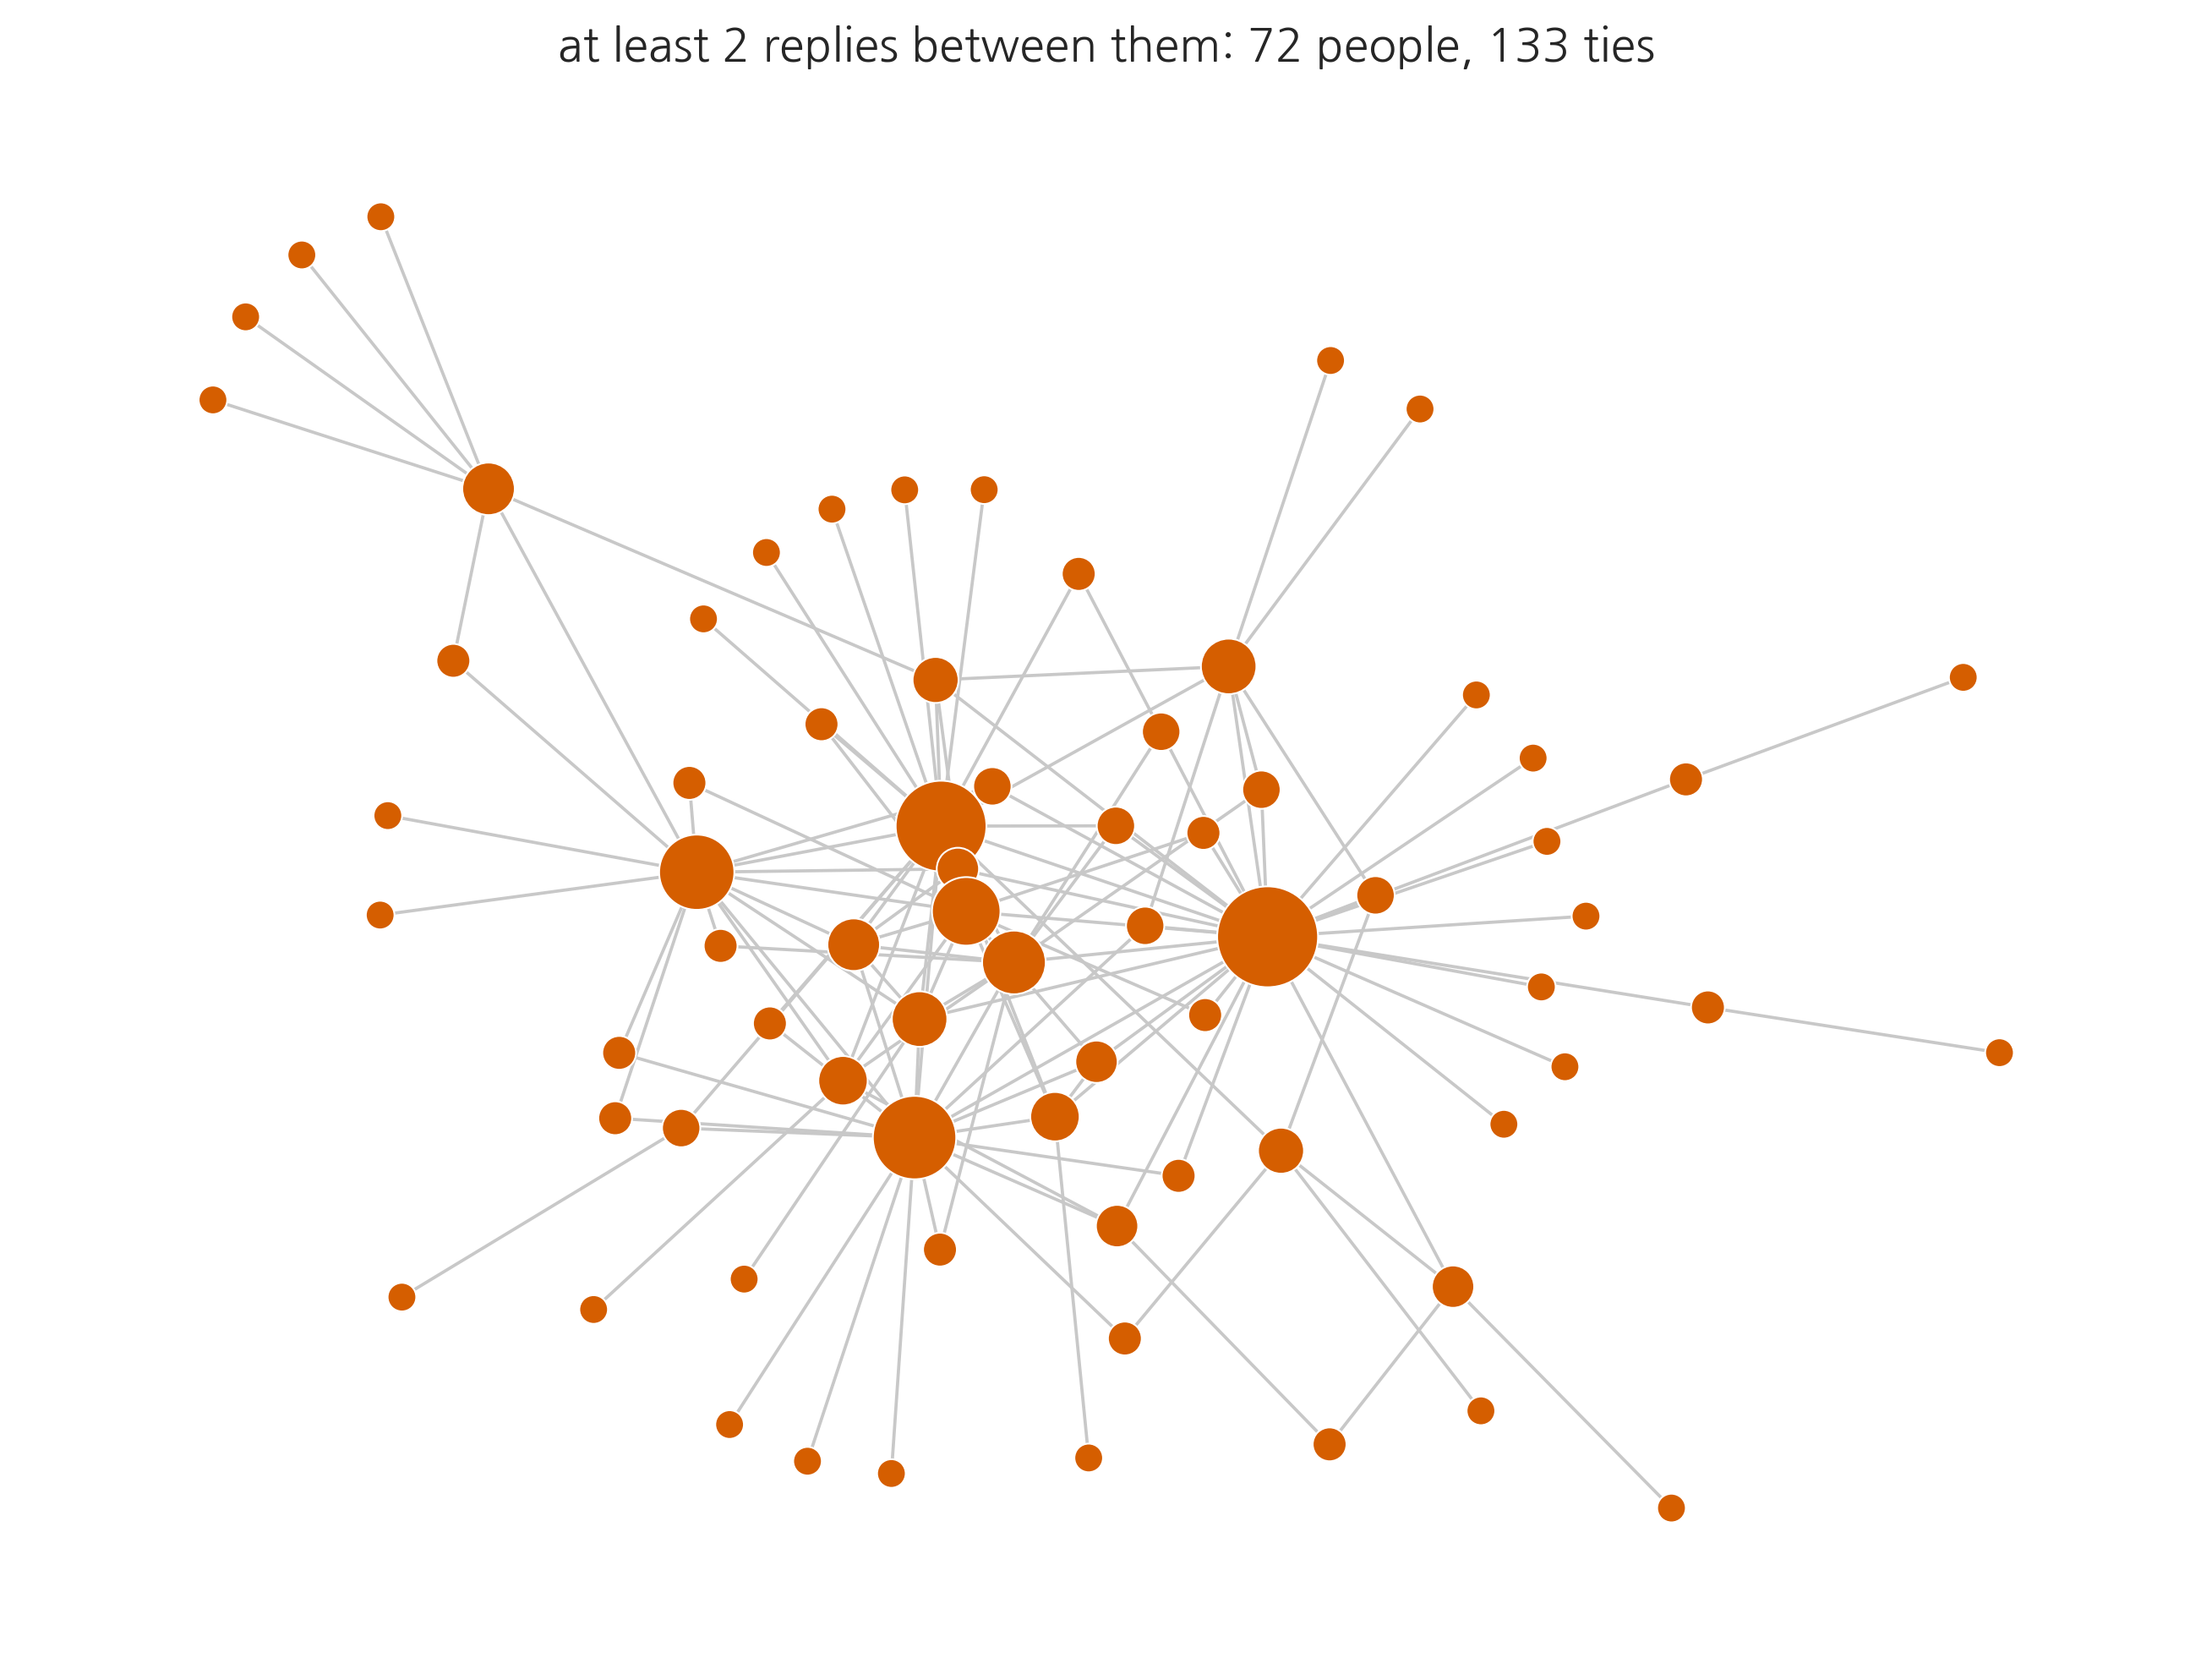

In [7]:
MIN_REPLIES = 2        # change this to 1, 2, 3 ...

counts = {}
for _, r in posts.dropna(subset=["parent_post_id"]).iterrows():
    t = author_of.get(r.parent_post_id)
    if t and t != r.author:
        k = tuple(sorted((r.author, t)))
        counts[k] = counts.get(k, 0) + 1

H = nx.Graph()
H.add_edges_from([k for k, v in counts.items() if v >= MIN_REPLIES])
K = H.subgraph(max(nx.connected_components(H), key=len)).copy() if H.number_of_edges() else H

p = nx.spring_layout(K, seed=8100, k=0.6, iterations=250)
d = dict(K.degree())
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(K, p, ax=ax, edge_color="#c8c8c8", width=0.9)
nx.draw_networkx_nodes(K, p, ax=ax, node_color="#d55e00",
                       node_size=[40 + 26 * d[n] for n in K.nodes()], edgecolors="white", linewidths=0.5)
ax.set_title(f"at least {MIN_REPLIES} replies between them: "
             f"{K.number_of_nodes()} people, {K.number_of_edges()} ties", fontsize=13)
ax.axis("off"); plt.show()

## Read the posts

Pull what one person actually wrote.

In [8]:
WHO = cent.index[0]        # the highest degree; change to any author id

print(f"{deg[WHO]} ties, {int(cent.loc[WHO, 'posts written'])} posts\n")
for _, r in posts[posts.author == WHO].head(12).iterrows():
    print(f"[{r.category_name}] {str(r.body)[:150]}")

58 ties, 132 posts

[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] And this is what is incorrectly marked as correct:     ![failure trace error][1]     [1]: https://edxuploads.s3.amazonaws.com/14626129267029983.png
[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] The wording of the question is misleading.        The expected values in the test itself are not correct → the question should read :     What are/wou
[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] Thank you florina - the text is much clearer now!
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.     → Any negative input will lead to a stack overflow     → Negative inputs are lega
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.   → Any negative input will lead to a stack overflow      → Negative inputs are legal
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.    → Any negati

1. Does the person with the highest degree look like the most important person in the forum?
2. The three rules in section 2 gave three different networks. What decides which one you use?
3. What happened in this forum that none of these networks can see?